In [33]:
import sys
from pathlib import Path
import importlib

import yaml

import pandas as pd
import numpy as np

sys.path.insert(0, str(Path.cwd().resolve().parents[0] / 'src'))

from ipfnpytools.plot import use_base_style
from ts_profile_fitter.loading import load_shot_list, load_ts_data, load_intervals
import ts_profile_fitter.preprocess as preprocess
importlib.reload(preprocess)
from ts_profile_fitter.preprocess import (
    apply_cold_dense_edge_filters,
    apply_distance_outlier_filters,
    map_to_r_midplane,
    preprocess_ts_data,
)
from ts_profile_fitter.fitting import (
    compute_channel_knots,
    fit_ipfn_spline_ne_Te_TS,
    fit_modified_tanh_profile,
    fit_mbsplt_ne_Te_TS,
)
from ts_profile_fitter.derived_quantities import compute_profile_quantities
from ts_profile_fitter.figure_naming import make_fig_name

# Configuration

This section contains the inputs and choices that define one reproducible shot/interval run. The later cells are grouped into preprocessing, fitting, physics, and plotting stages.

In [34]:
repo_root = Path.cwd().resolve().parent
config_path = repo_root / 'configs' / 'pipeline_config_run_02.yaml'
config_dir = config_path.parent
with config_path.open('r', encoding='utf-8') as stream:
    pipeline_config = yaml.safe_load(stream) or {}

def resolve_config_path(value, default):
    path = pipeline_config.get(value, default)
    path = Path(path)
    return path if path.is_absolute() else config_dir / path

fit_config = pipeline_config.get('fit_config', {})
preprocess_config = fit_config.get('preprocess', {})
fits_config = fit_config.get('fits', {})
physics_config = fit_config.get('physics', {})

shot_id = 36124
time_requested = 6.6
equilibrium = pipeline_config.get('equilibrium', 'EQH')
data_directory = str(resolve_config_path('data_dir', '../data'))
intervals_path = str(resolve_config_path('database', '../data/intervals.csv'))
output_directory = repo_root / 'plots'
mapping_method = preprocess_config.get('mapping_method', 'ipfnpytools')
r_edge_offset = preprocess_config.get('r_edge_offset', 0.008)
r_zoom = 2.12
r_zoom_max = 2.16
physics_grid_size = physics_config.get('grid_size', 2000)
knot_count_shift = fits_config.get('spline', {}).get('knot_count_shift', 0)

# Notebook plotting controls are intentionally independent of the YAML.
save_figures = False
show_figures = True
close_figures = False

# Parse preprocess configurations from .yaml
rhop_filter = preprocess_config.get('rhop_filter', {})
outlier_config = preprocess_config.get('outlier_config', {})
cold_dense_edge_config = preprocess_config.get('cold_dense_edge_config', {})

# Parse fit configs from .yaml
mtanh_config = fits_config.get('mtanh', {})
spline_config = fits_config.get('spline', {})


print(f'Loaded configuration: {config_path}')
print(f'Using database: {intervals_path}')
print(f'Notebook plotting: save={save_figures}, show={show_figures}, close={close_figures}')

Loaded configuration: /shares/users/work/joanune/Desktop/TS_profile_fitter/configs/pipeline_config_run_02.yaml
Using database: /shares/users/work/joanune/Desktop/TS_profile_fitter/data/34383---38808_database_dt-0.1s.pkl
Notebook plotting: save=False, show=True, close=False


In [35]:
intervals_df = load_intervals(intervals_path)

shot_intervals = intervals_df[intervals_df['shot_id'] == shot_id]
matching_intervals = shot_intervals[
    (shot_intervals['t_begin'] <= time_requested)
    & (time_requested <= shot_intervals['t_end'])
]
if matching_intervals.empty:
    raise ValueError(
        f'No interval found for shot {shot_id} at t={time_requested:.3f} s.'
    )

selected_interval = matching_intervals.iloc[0]
interval = {
    't_begin': float(selected_interval['t_begin']),
    't_end': float(selected_interval['t_end']),
    'label': selected_interval['label'],
}

print(
    f"Shot {shot_id}, t={time_requested:.3f} s -> "
    f"({interval['t_begin']:.3f}, {interval['t_end']:.3f}) s: {interval['label']}"
)

Shot 36124, t=6.600 s -> (6.567, 6.663) s: developed calm EDA H-mode (with QCM)


In [36]:
shot_intervals = intervals_df[intervals_df['shot_id'] == shot_id]
shot_intervals[['t_begin', 't_end', 'label']].tail(20)

,t_begin,t_end,label
215,5.000000,5.125000,developed calm EDA H-mode (with QCM)
216,5.125000,5.250000,developed calm EDA H-mode (with QCM)
217,5.250000,5.356667,developed pulsating EDA H-mode (with QCM)
218,5.356667,5.463333,developed pulsating EDA H-mode (with QCM)
219,5.463333,5.570000,developed pulsating EDA H-mode (with QCM)
220,5.570000,5.676667,developed pulsating EDA H-mode (with QCM)
221,5.676667,5.783333,developed pulsating EDA H-mode (with QCM)
222,5.783333,5.890000,developed pulsating EDA H-mode (with QCM)
223,5.890000,5.986667,developed calm EDA H-mode (with QCM)
224,5.986667,6.083333,developed calm EDA H-mode (with QCM)


In [37]:
import importlib
import ts_profile_fitter.preprocess as preprocess

importlib.reload(preprocess)

<module 'ts_profile_fitter.preprocess' from '/shares/users/work/joanune/Desktop/TS_profile_fitter/src/ts_profile_fitter/preprocess.py'>

In [38]:
ts_dict = load_ts_data(shot_id=shot_id, data_dir=data_directory, equilibrium=equilibrium)
ts_df, preprocess_metadata = preprocess_ts_data(
    ts_dict,
    interval=interval,
    r_edge_offset=r_edge_offset,
    mapping_method=mapping_method,
    outlier_config=outlier_config,
    rhop_filter=rhop_filter,
    report_outliers=True,
    return_metadata=True,
)
'''
# Remove edge points at the cold, high-density fit boundary.
cold_dense_edge_config = {
    'enabled': True,
    'te_max': 1.1,
    'ne_min': 2.0e19,
} '''
ts_df, cold_dense_edge_metadata = apply_cold_dense_edge_filters(
    ts_df,
    cold_dense_config=cold_dense_edge_config,
    report=True,
    return_metadata=True,
)
print('Cold-dense edge outliers:', cold_dense_edge_metadata['filter_counts'])
if not cold_dense_edge_metadata['removed_rows'].empty:
    print(cold_dense_edge_metadata['removed_rows'][[
        'system', 'channel_index', 'time', 'r_midplane',
        'Te', 'Te_err', 'Ne', 'Ne_err', 'filter_reason',
    ]].to_string(index=False))
'''
# Second pass: target isolated high-Ne points with unrealistically small errors.
distance_outlier_config = {
    'Ne_edge': {
        'enabled': True,
        'n_neighbors': 5,
        'min_points': 3,
        'min_value': 2.0e19,
        'max_relative_error': 0.05,
        'zscore': 5.0,
        'min_scale': 1.0e18,
    },
}
ts_df, distance_outlier_metadata = apply_distance_outlier_filters(
    ts_df,
    distance_outlier_config=distance_outlier_config,
    report=True,
    return_metadata=True,
)
print('Second-pass distance outliers:', distance_outlier_metadata['filter_counts'])
if not distance_outlier_metadata['removed_rows'].empty:
    print(distance_outlier_metadata['removed_rows'][[
        'system', 'channel_index', 'time', 'r_midplane',
        'Ne', 'Ne_err', 'filter_reason',
    ]].to_string(index=False)) '''

#ts_df.head()
ts_df = map_to_r_midplane(ts_df)
ts_df.head()

00:29:56 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/VTA/36/36124.2
00:29:56 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/EQH/36/36124.1
00:29:56 | aug_sfutils.sf2equ | INFO: Reading equ scalars
00:29:56 | aug_sfutils.sf2equ | INFO: Reading equ 1d profiles
00:29:57 | aug_sfutils.sf2equ | INFO: Reading equ PFM
00:29:57 | aug_sfutils.sf2equ | INFO: COCO 17


Dimensions before mapping: time: (5, 1) r: (5, 1) z: (1, 16)
Dimensions before mapping: time: (12, 1) r: (12, 1) z: (1, 11)


/u/joanune/ipfnpytools/ipfnpytools/trz_to_rhop.py:61: RuntimeWarning: invalid value encountered in sqrt
  values=np.array(np.sqrt((eq.pfm - eq.psi0)/(eq.psix-eq.psi0)), dtype=np.float32),
/u/joanune/ipfnpytools/ipfnpytools/trhopz_to_r.py:124: RuntimeWarning: invalid value encountered in sqrt
  values=np.array(np.swapaxes(np.sqrt((eq.pfm - eq.psi0)/(eq.psix-eq.psi0)), 0, 2), dtype=data_type),


Removed 4 core TS channels (15 rows); removed 0 edge TS channels (0 rows).
[Outlier Filtering Report: core:Te]
→ Total outliers removed: 0
  (Note: A point may be removed for multiple reasons.)
  - nonfinite: 0 points
  - value < min: 0 points
  - value > max: 0 points
  - value == 0: 0 points
  - error == 0: 0 points
[Outlier Filtering Report: core:Ne]
→ Total outliers removed: 0
  (Note: A point may be removed for multiple reasons.)
  - nonfinite: 0 points
  - value < min: 0 points
  - value > max: 0 points
  - value == 0: 0 points
  - error == 0: 0 points
[Outlier Filtering Report: edge:Te]
→ Total outliers removed: 18
  (Note: A point may be removed for multiple reasons.)
  - nonfinite: 0 points
  - value < min: 0 points
  - value > max: 7 points
  - error > max: 9 points
  - value == 0: 9 points
  - error == 0: 9 points
[Outlier Filtering Report: edge:Ne]
→ Total outliers removed: 10
  (Note: A point may be removed for multiple reasons.)
  - nonfinite: 0 points
  - value < min: 5 

,system,channel_index,time,r_channel,z_channel,rho_pol,r_midplane,Te,Te_err,Ne,Ne_err,keep,filter_reason
20,core,4,6.607113,1.78095,0.009,0.200805,1.785346,2685.041016,120.001480,9.217905e+19,1.963192e+18,True,
68,core,4,6.657107,1.78095,0.009,0.200520,1.785619,2991.733643,137.731628,9.593500e+19,1.948005e+18,True,
51,core,3,6.623734,1.78635,0.066,0.205804,1.788210,3365.781982,193.083282,9.820022e+19,2.240701e+18,True,
52,core,4,6.623734,1.78635,0.009,0.211896,1.790801,3282.803711,182.332520,9.326913e+19,2.130957e+18,True,
4,core,4,6.573740,1.78635,0.009,0.203840,1.791892,3300.848633,172.805084,9.310092e+19,2.006200e+18,True,


In [39]:
df_te = ts_df[['r_midplane', 'Te', 'Te_err']].dropna().sort_values('r_midplane')
df_ne = ts_df[['r_midplane', 'Ne', 'Ne_err']].dropna().sort_values('r_midplane')

In [40]:
fit_params = {}

# Temperature fit: uses the fitter's internal min/max-based initial guess.
te_popt, te_pcov = fit_modified_tanh_profile(
    df_te['r_midplane'].to_numpy(),
    df_te['Te'].to_numpy(),
    df_te['Te_err'].to_numpy(),
    **mtanh_config['Te'],
)
fit_params['Te'] = te_popt
print('Te mtanh params:', te_popt)

# Density fit: independent call, with its own polynomial orders.
ne_popt, ne_pcov = fit_modified_tanh_profile(
    df_ne['r_midplane'].to_numpy(float),
    df_ne['Ne'].to_numpy(float),
    df_ne['Ne_err'].to_numpy(float),
    **mtanh_config['Ne'],
)
fit_params['Ne'] = ne_popt
print('Ne mtanh params:', ne_popt)


Te mtanh params: [ 2.14115350e+00  3.78217213e-03  0.00000000e+00  2.67755765e+02
  0.00000000e+00  0.00000000e+00  3.32417768e+02 -4.85293958e+03
 -2.37852468e+04 -9.38492323e+04]
Ne mtanh params: [ 2.13791599e+00  1.26641009e-02  2.30627648e+18 -1.28521154e+19
 -2.06930305e+19  0.00000000e+00  7.67925430e+19  2.39670939e+20
  1.80306880e+21  2.82923789e+21]


In [41]:
x_ne = df_ne['r_midplane'].to_numpy()
y_ne = df_ne['Ne'].to_numpy()
yerr_ne = df_ne['Ne_err'].to_numpy()
print('Ne points:', len(x_ne))
print('Ne x range:', x_ne.min(), x_ne.max())
print('Ne y range:', y_ne.min(), y_ne.max())
print('Ne error range:', yerr_ne.min(), yerr_ne.max())
print('Unique x values:', np.unique(x_ne).size)

Ne points: 169
Ne x range: 1.785346269607544 2.2382419109344482
Ne y range: 6.382097e+17 1.0164153e+20
Ne error range: 2.9461253e+17 4.456245e+18
Unique x values: 147


In [42]:
x_te = df_te['r_midplane'].to_numpy()
y_te = df_te['Te'].to_numpy()
yerr_te = df_te['Te_err'].to_numpy()
print('Te points:', len(x_te))
print('Te x range:', x_te.min(), x_te.max())
print('Te y range:', y_te.min(), y_te.max())
print('Te error range:', yerr_te.min(), yerr_te.max())
print('Unique x values:', np.unique(x_te).size)

Te points: 169
Te x range: 1.785346269607544 2.2382419109344482
Te y range: 8.539071 3843.6863
Te error range: 1.8107133 311.96423
Unique x values: 147


In [43]:
df_spline = ts_df[[
    'system',
    'r_channel',
    'r_midplane',
    'Ne',
    'Ne_err',
    'Te',
    'Te_err',
]].dropna().sort_values('r_midplane')

ds_spline_knots = df_spline.drop(columns=['r_channel']).rename(columns={
    'r_midplane': 'R_mid',
    'Ne': 'ne',
    'Ne_err': 'ne_err',
})
ds_spline_input = ds_spline_knots.drop(columns=['system'])
knots = compute_channel_knots(
    ds_spline_knots,
    preprocess_metadata['channels_before'],
    preprocess_metadata['channels_removed'],
    knot_count_shift=knot_count_shift,
    strategy=spline_config.get('knot_strategy', 'global_quantile'),
)
print(f'Computed {len(knots)} spline knots: {knots}')

Computed 11 spline knots: [1.78534627 1.84439596 1.96504084 2.1159153  2.12587047 2.13432574
 2.14114428 2.14919043 2.16082756 2.180329   2.23824191]


In [44]:
ds_spline_input['R_mid'] 

20     1.785346
68     1.785619
51     1.788210
52     1.790801
4      1.791892
         ...   
124    2.225287
201    2.227878
91     2.232651
168    2.236742
113    2.238242
Name: R_mid, Length: 169, dtype: float64

In [45]:
# RELOAD PLOTTING MODULE

import importlib
import ts_profile_fitter.plotting as plotting

importlib.reload(plotting)
use_base_style()

plot_profile_fit = plotting.plot_profile_fit
plot_spline_profile_fit = plotting.plot_spline_profile_fit

# Figure names are initialized before any production plot is created.
n_channels_core = preprocess_metadata['channels_before']['core']
n_channels_edge = preprocess_metadata['channels_before']['edge']
channels_rmvd = preprocess_metadata['channels_removed']['core']
n_knots = len(knots)
figure_names = {
    'ne_mtanh_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_mtanh_full'),
    'te_mtanh_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_mtanh_full'),
    'ne_spline_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_spline_full'),
    'te_spline_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_spline_full'),
    'ne_compare_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_compare_full'),
    'ne_compare_zoom': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_compare_zoom'),
    'te_compare_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_compare_full'),
    'te_compare_zoom': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_compare_zoom'),
    'summary_all': make_fig_name(shot_id, equilibrium, n_knots, interval, 'summary_all'),
}

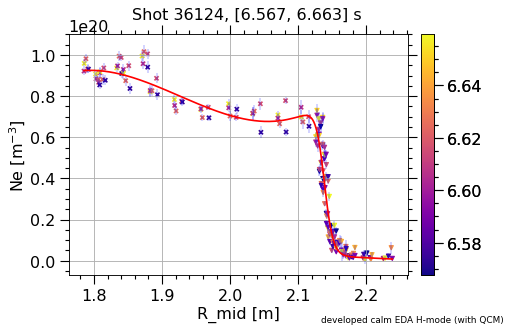

'shot36124_EQH_k11_t6p567-6p663_ne_mtanh_full'

In [46]:
from ts_profile_fitter.plotting import plot_profile_fit

# Use the core/edge labels created by preprocessing.
df_plot_ne = ts_df.dropna(
    subset=['system', 'r_midplane', 'Ne', 'Ne_err', 'time']
)
core_ne = df_plot_ne['system'] == 'core'
edge_ne = df_plot_ne['system'] == 'edge'

fig, ax = plot_profile_fit(
    x_core=df_plot_ne.loc[core_ne, 'r_midplane'].to_numpy(),
    x_edge=df_plot_ne.loc[edge_ne, 'r_midplane'].to_numpy(),
    y_core=df_plot_ne.loc[core_ne, 'Ne'].to_numpy(),
    y_edge=df_plot_ne.loc[edge_ne, 'Ne'].to_numpy(),
    y_err_core=df_plot_ne.loc[core_ne, 'Ne_err'].to_numpy(),
    y_err_edge=df_plot_ne.loc[edge_ne, 'Ne_err'].to_numpy(),
    x_labels='R_mid [m]',
    y_labels='Ne [m$^{-3}$]',
    time_c=df_plot_ne.loc[core_ne, 'time'].to_numpy(),
    time_e=df_plot_ne.loc[edge_ne, 'time'].to_numpy(),
    popt=fit_params['Ne'],
    directory=output_directory,
    close=close_figures,
    save_fig=save_figures,
    show=show_figures,
    nshot=shot_id,
    interval=interval,
    fig_name=figure_names['ne_mtanh_full'],
)
figure_names['ne_mtanh_full']

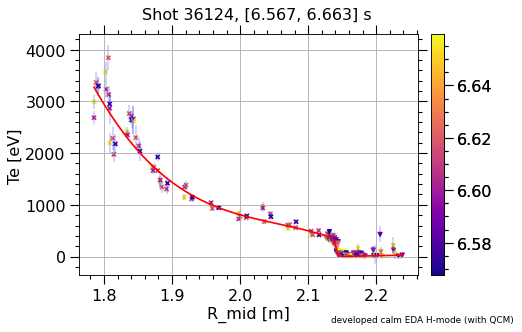

'shot36124_EQH_k11_t6p567-6p663_te_mtanh_full'

In [47]:
# Temperature plot using the original core/edge system labels.
df_plot_te = ts_df.dropna(
    subset=['system', 'r_midplane', 'Te', 'Te_err', 'time']
)
core_te = df_plot_te['system'] == 'core'
edge_te = df_plot_te['system'] == 'edge'

fig, ax = plot_profile_fit(
    x_core=df_plot_te.loc[core_te, 'r_midplane'].to_numpy(),
    x_edge=df_plot_te.loc[edge_te, 'r_midplane'].to_numpy(),
    y_core=df_plot_te.loc[core_te, 'Te'].to_numpy(),
    y_edge=df_plot_te.loc[edge_te, 'Te'].to_numpy(),
    y_err_core=df_plot_te.loc[core_te, 'Te_err'].to_numpy(),
    y_err_edge=df_plot_te.loc[edge_te, 'Te_err'].to_numpy(),
    x_labels='R_mid [m]',
    y_labels='Te [eV]',
    time_c=df_plot_te.loc[core_te, 'time'].to_numpy(),
    time_e=df_plot_te.loc[edge_te, 'time'].to_numpy(),
    popt=fit_params['Te'],
    directory=output_directory,
    close=close_figures,
    save_fig=save_figures,
    show=show_figures,
    nshot=shot_id,
    interval=interval,
    fig_name=figure_names['te_mtanh_full'],
)
figure_names['te_mtanh_full']

In [48]:
spline_method = spline_config.get('method', 'ondrej_spline')
if spline_method == 'ondrej_spline':
    ds_out, xt, p_ne, pcov_ne, p_Te, pcov_Te = fit_mbsplt_ne_Te_TS(
        ds_spline_input,
        dR_fine=spline_config.get('dR_fine', 5e-4),
        sigma_conv=spline_config.get('sigma_conv', 5e-3),
        R_knots=knots,
        dR_channel_max=spline_config.get('dR_channel_max', 3e-3),
        max_step_scale=spline_config.get('max_step_scale', 3),
        use_errors=spline_config.get('use_errors', True),
        loss=spline_config.get('loss', 'linear'),
        f_scale=spline_config.get('f_scale', 1.0),
        ne_scale=spline_config.get('ne_scale', 1e19),
        Te_scale=spline_config.get('Te_scale', 1e3),
    )
elif spline_method == 'ipfn_spline':
    ds_out, xt, p_ne, pcov_ne, p_Te, pcov_Te = fit_ipfn_spline_ne_Te_TS(
        ds_spline_input,
        dR_fine=spline_config.get('dR_fine', 5e-4),
        R_knots=knots,
        dR_channel_max=spline_config.get('dR_channel_max', 3e-3),
        ne_scale=spline_config.get('ne_scale', 1e19),
        Te_scale=spline_config.get('Te_scale', 1e3),
        s_factor=spline_config.get('s_factor', 1.0),
        s=spline_config.get('s'),
        mono=spline_config.get('mono', 'decreasing'),
        bc_type=spline_config.get('bc_type'),
        maxiter=spline_config.get('maxiter', 200),
        minimize_kw=spline_config.get('minimize_kw'),
    )
else:
    raise ValueError(
        f'Unknown spline method {spline_method!r}; expected '
        "'ondrej_spline' or 'ipfn_spline'."
    )

print(f'Spline fit completed with method: {spline_method}')
print('Knot count shift:', knot_count_shift)
print('Number of knots:', len(knots))
print('Knot locations:', knots)
print('Ne parameters:', p_ne)
print('Te parameters:', p_Te)
print(ds_out.head().to_string(index=False))

Spline fit completed with method: ipfn_spline
Knot count shift: 0
Number of knots: 11
Knot locations: [1.78534627 1.84439596 1.96504084 2.1159153  2.12587047 2.13432574
 2.14114428 2.14919043 2.16082756 2.180329   2.23824191]
Ne parameters: [9.38527621e+19 9.05046132e+19 9.55501270e+19 6.25998282e+19
 7.36171335e+19 6.59038046e+19 5.05741992e+19 3.13426406e+19
 6.12703248e+18 3.42977242e+18 3.96576158e+17 1.35243984e+18
 9.57755850e+17]
Te parameters: [3064.8842075  3064.91108103 1593.96682675  737.94851154  675.99490378
  402.85441091  430.56663099   64.94595285   34.23082922   22.51205857
    3.86800047   12.74955969    6.78141963]
 R_mid_spl       ne_spl       dne_spl  lam_ne_spl      Te_spl      dTe_spl   lam_Te_spl
  1.785346 9.385276e+19 -1.701016e+20    0.551745 3064.884208     1.365301 -2244.841942
  1.787346 9.352950e+19 -1.533092e+20    0.610071 3063.246339 -1627.733454     1.881909
  1.789346 9.323894e+19 -1.373893e+20    0.678648 3058.419276 -3187.828640     0.959405
  1.79

# Figure Naming

Every saved figure uses the shot, equilibrium, knot count, exact interval bounds, and a controlled plot descriptor.

In [49]:
figure_names = {
    'ne_mtanh_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_mtanh_full'),
    'te_mtanh_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_mtanh_full'),
    'ne_spline_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_spline_full'),
    'te_spline_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_spline_full'),
    'ne_compare_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_compare_full'),
    'ne_compare_zoom': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_compare_zoom'),
    'te_compare_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_compare_full'),
    'te_compare_zoom': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_compare_zoom'),
    'summary_all': make_fig_name(shot_id, equilibrium, n_knots, interval, 'summary_all'),
}
figure_names

{'ne_mtanh_full': 'shot36124_EQH_k11_t6p567-6p663_ne_mtanh_full',
 'te_mtanh_full': 'shot36124_EQH_k11_t6p567-6p663_te_mtanh_full',
 'ne_spline_full': 'shot36124_EQH_k11_t6p567-6p663_ne_spline_full',
 'te_spline_full': 'shot36124_EQH_k11_t6p567-6p663_te_spline_full',
 'ne_compare_full': 'shot36124_EQH_k11_t6p567-6p663_ne_compare_full',
 'ne_compare_zoom': 'shot36124_EQH_k11_t6p567-6p663_ne_compare_zoom',
 'te_compare_full': 'shot36124_EQH_k11_t6p567-6p663_te_compare_full',
 'te_compare_zoom': 'shot36124_EQH_k11_t6p567-6p663_te_compare_zoom',
 'summary_all': 'shot36124_EQH_k11_t6p567-6p663_summary_all'}

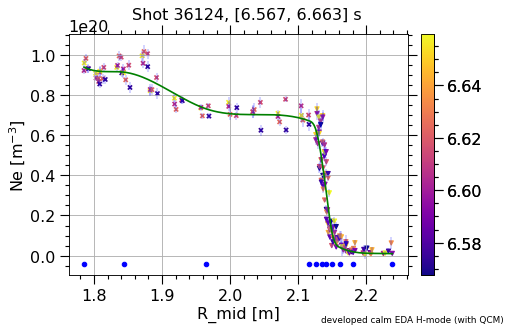

(<Figure size 535.433x330.916 with 3 Axes>,
 <Axes: xlabel='R_mid [m]', ylabel='Ne [m$^{-3}$]'>)

In [50]:
from ts_profile_fitter.plotting import plot_spline_profile_fit

df_plot = ts_df.dropna(
    subset=['system', 'r_midplane', 'Ne', 'Ne_err', 'Te', 'Te_err', 'time']
)

core = df_plot['system'] == 'core'
edge = df_plot['system'] == 'edge'

# Density spline plot
plot_spline_profile_fit(
    x_core=df_plot.loc[core, 'r_midplane'].to_numpy(),
    x_edge=df_plot.loc[edge, 'r_midplane'].to_numpy(),
    y_core=df_plot.loc[core, 'Ne'].to_numpy(),
    y_edge=df_plot.loc[edge, 'Ne'].to_numpy(),
    y_err_core=df_plot.loc[core, 'Ne_err'].to_numpy(),
    y_err_edge=df_plot.loc[edge, 'Ne_err'].to_numpy(),
    ds_out=ds_out,
    quantity='Ne',
    knot_pos=knots,
    x_labels='R_mid [m]',
    y_labels='Ne [m$^{-3}$]',
    time_c=df_plot.loc[core, 'time'].to_numpy(),
    time_e=df_plot.loc[edge, 'time'].to_numpy(),
    directory=output_directory,
    nshot=shot_id,
    interval=interval,
    fig_name=figure_names['ne_spline_full'],
    show=show_figures,
    close=close_figures,
    save_fig=save_figures,
)


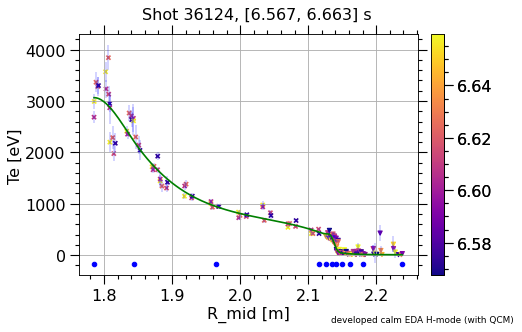

(<Figure size 535.433x330.916 with 3 Axes>,
 <Axes: xlabel='R_mid [m]', ylabel='Te [eV]'>)

In [51]:
core = df_plot['system'] == 'core'
edge = df_plot['system'] == 'edge'

# Temperature spline plot
plot_spline_profile_fit(
    x_core=df_plot.loc[core, 'r_midplane'].to_numpy(),
    x_edge=df_plot.loc[edge, 'r_midplane'].to_numpy(),
    y_core=df_plot.loc[core, 'Te'].to_numpy(),
    y_edge=df_plot.loc[edge, 'Te'].to_numpy(),
    y_err_core=df_plot.loc[core, 'Te_err'].to_numpy(),
    y_err_edge=df_plot.loc[edge, 'Te_err'].to_numpy(),
    ds_out=ds_out,
    quantity='Te',
    knot_pos=knots,
    x_labels='R_mid [m]',
    y_labels='Te [eV]',
    time_c=df_plot.loc[core, 'time'].to_numpy(),
    time_e=df_plot.loc[edge, 'time'].to_numpy(),
    directory=output_directory,
    nshot=shot_id,
    interval=interval,
    fig_name=figure_names['te_spline_full'],
    show=show_figures,
    close=close_figures,
    save_fig=save_figures,
)


In [52]:
ds_out.head().to_string(index=False)

' R_mid_spl       ne_spl       dne_spl  lam_ne_spl      Te_spl      dTe_spl   lam_Te_spl\n  1.785346 9.385276e+19 -1.701016e+20    0.551745 3064.884208     1.365301 -2244.841942\n  1.787346 9.352950e+19 -1.533092e+20    0.610071 3063.246339 -1627.733454     1.881909\n  1.789346 9.323894e+19 -1.373893e+20    0.678648 3058.419276 -3187.828640     0.959405\n  1.791346 9.297936e+19 -1.223419e+20    0.759996 3050.541027 -4678.920259     0.651975\n  1.793346 9.274899e+19 -1.081670e+20    0.857461 3039.749597 -6101.008308     0.498237'

In [53]:
# Load interval-averaged power-balance and geometry inputs.
sys.path.insert(0, '/shares/users/work/joanune/Desktop/pysepest')

import ts_profile_fitter.loading as loading
importlib.reload(loading)
load_physics_inputs = loading.load_physics_inputs

import ts_profile_fitter.fitting as fitting
importlib.reload(fitting)
modified_tanh = fitting.modified_tanh

import ts_profile_fitter.derived_quantities as derived_quantities
importlib.reload(derived_quantities)
compute_equilibrium_separatrix = derived_quantities.compute_equilibrium_separatrix
compute_physics_separatrix = derived_quantities.compute_physics_separatrix
get_connection_length = derived_quantities.get_connection_length

from pysepest.optimizers import first_0_crossing

physics_inputs = load_physics_inputs(
    shot_id,
    interval,
    equilibrium='EQH',
)

power_balance = physics_inputs['power_balance']
geometry = physics_inputs['geometry']
print('Power-balance inputs:', power_balance)
print('Geometry inputs:', geometry)


00:30:11 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/EQH/36/36124.1


00:30:11 | aug_sfutils.sf2equ | INFO: Reading equ scalars
00:30:11 | aug_sfutils.sf2equ | INFO: Reading equ 1d profiles
00:30:12 | aug_sfutils.sf2equ | INFO: Reading equ PFM
00:30:12 | aug_sfutils.sf2equ | INFO: COCO 17
00:30:13 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/TTH/36/36124.1
00:30:13 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/davidp/BPT/36/36124.4
00:30:13 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/TOT/36/36124.1
00:30:13 | aug_sfutils.sfread | ERROR: Shotfile not found for AUGD:ELM(0) #36124
00:30:13 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/GQH/36/36124.1
00:30:13 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/FPC/36/36124.1
00:30:13 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/MBI/36/36124.1
00:30:13 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug

Magnetic Fields:
B_pol_analytic: 0.2255163433081669, B_pol_out: 0.30652696331317886, B_tor_out: -1.9246726036071777, B_tor_mbi: -2.4969583098421393
Power-balance inputs: {'P_abs': 2641313.8891752576, 'P_rsep': 916845.9583333334, 'dWdt': 0.0, 'dWdt_err': 0.0}
Geometry inputs: {'R_out': 2.144429922103882, 'B_pol': 0.30652696331317886, 'B_tor': -1.9246726036071777, 'Z_eff': 1.5}


In [54]:
ts_dict['equ'].time

SFOBJ([0.0606, 0.0626, 0.0686, ..., 7.8676, 7.8686, 7.8696], dtype='>f4')

In [55]:
# Add connection length and compute all three separatrix locations.
sys.path.insert(0, '/shares/users/work/joanune/Desktop/aug_separatrix')
from get_connection_length import get_LcSOL

L_par = get_connection_length(
    shot_id,
    interval,
    provider=get_LcSOL,
    dR=1e-3,
)
geometry['L_par'] = L_par
print('Connection length [m]:', L_par)

# Equilibrium-defined separatrix: rho_pol = 1 at the outer midplane.
eqh_result = compute_equilibrium_separatrix(
    ts_dict['equ'],
    interval,
    rho_sep=1.0,
)
print('EQH Rsep [m]:', eqh_result['Rsep_eqh'])

R_min = max(df_te['r_midplane'].min(), df_ne['r_midplane'].min())
R_max = min(df_te['r_midplane'].max(), df_ne['r_midplane'].max())
R_test = np.linspace(R_min, R_max, physics_grid_size)

mtanh_result = compute_physics_separatrix(
    R=R_test,
    Te=modified_tanh(R_test, *te_popt),
    Ne=modified_tanh(R_test, *ne_popt),
    power_balance=power_balance,
    geometry=geometry,
    fit_method='mtanh',
    optimizer=first_0_crossing,
)

spline_result = compute_physics_separatrix(
    R=ds_out['R_mid_spl'].to_numpy(),
    Te=ds_out['Te_spl'].to_numpy(),
    Ne=ds_out['ne_spl'].to_numpy(),
    dTe_dR=ds_out['dTe_spl'].to_numpy(),
    dNe_dR=ds_out['dne_spl'].to_numpy(),
    power_balance=power_balance,
    geometry=geometry,
    fit_method='spline',
    optimizer=first_0_crossing,
)

print('mtanh Rsep [m]:', mtanh_result['Rsep'])
print('spline Rsep [m]:', spline_result['Rsep'])
print('mtanh Te_sep [eV]:', mtanh_result.get('Te_sep'))
print('spline Te_sep [eV]:', spline_result.get('Te_sep'))
print('mtanh mismatch:', mtanh_result.get('model_mismatch'))
print('spline mismatch:', spline_result.get('model_mismatch'))


00:30:14 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/EQH/36/36124.1
00:30:14 | aug_sfutils.manage_ed | WARNING: File /shares/experiments/aug-shotfiles/augd/MAY/edcntl_dir/36/ed_cntl not found
00:30:14 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/MAY/36/36124
00:30:15 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/EQH/36/36124.1
00:30:15 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/GQH/36/36124.1
00:30:15 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/FPC/36/36124.1
/u/joanune/ipfnpytools/ipfnpytools/trhopz_to_r.py:124: RuntimeWarning: invalid value encountered in sqrt
  values=np.array(np.swapaxes(np.sqrt((eq.pfm - eq.psi0)/(eq.psix-eq.psi0)), 0, 2), dtype=data_type),


Connection length [m]: 32.213164011689585
EQH Rsep [m]: 2.145235538482666
mtanh Rsep [m]: 2.142149422710894
spline Rsep [m]: 2.1423195877710386
mtanh Te_sep [eV]: 121.80196595664151
spline Te_sep [eV]: 104.18090173791201
mtanh mismatch: -1524142.1916478872
spline mismatch: -481958.6006691754


In [56]:
spline_result['Rsep']

2.1423195877710386

In [57]:
mtanh_result['Rsep']

2.142149422710894

In [58]:
spline_result.keys()

dict_keys(['P_e_SOL', 'R', 'B_pol', 'B_tor', 'L_par', 'Zeff', 'q_distribution', 'Te', 'lam_Te', 'Ne', 'lam_Ne', 'lam_q', 'A_SOL', 'q_par_P_SOL', 'kappa_0', 'q_par_SH', 'x_sep', 'model_mismatch', 'Rsep', 'Te_sep', 'Ne_sep', 'P_SOL', 'fit_method', 'R_grid', 'mismatch_grid', 'Te_grid', 'lam_Te_grid', 'lam_q_grid', 'q_par_P_SOL_grid', 'q_par_SH_grid', 'optimizer_result'])

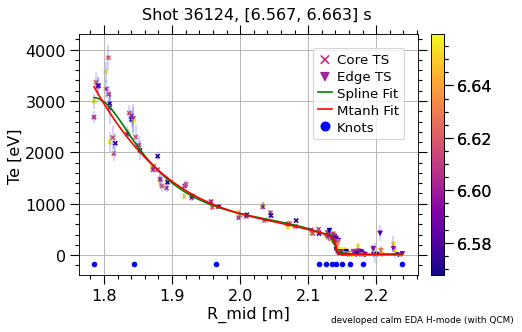

/shares/users/work/joanune/Desktop/TS_profile_fitter/src/ts_profile_fitter/plotting.py:646: UserWarning: not plotting dataset 1 due to ValueError: ('zero-size array to reduction operation fmax which has no identity',)
  return plot_profile_comparison(*args, **kwargs)


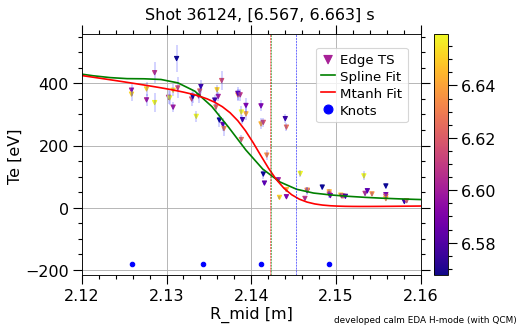

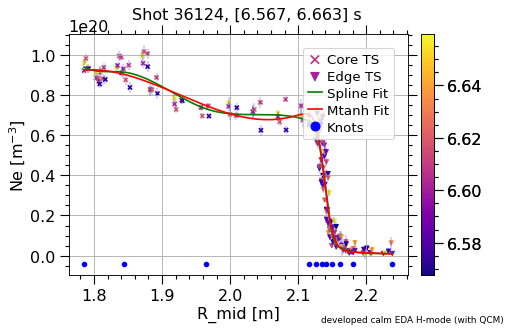

/shares/users/work/joanune/Desktop/TS_profile_fitter/src/ts_profile_fitter/plotting.py:646: UserWarning: not plotting dataset 1 due to ValueError: ('zero-size array to reduction operation fmax which has no identity',)
  return plot_profile_comparison(*args, **kwargs)


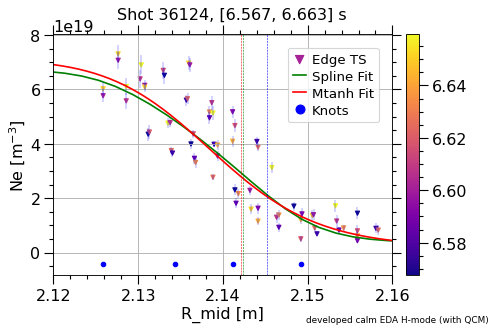

(<Figure size 535.433x330.916 with 2 Axes>,
 <Axes: xlabel='R_mid [m]', ylabel='Ne [m$^{-3}$]'>)

In [59]:
importlib.reload(plotting)

plot_profile_comparison_full = plotting.plot_profile_comparison_full
plot_profile_comparison_zoomed = plotting.plot_profile_comparison_zoomed

comparison_common = {
    'ds_out': ds_out,
    'knot_pos': knots,
    'nshot': shot_id,
    'interval': interval,
    'directory': output_directory,
    'show': show_figures,
    'close': close_figures,
    'save_fig': save_figures,
}

# Full-range temperature comparison
plot_profile_comparison_full(
    x_core=df_plot_te.loc[core_te, 'r_midplane'].to_numpy(),
    x_edge=df_plot_te.loc[edge_te, 'r_midplane'].to_numpy(),
    y_core=df_plot_te.loc[core_te, 'Te'].to_numpy(),
    y_edge=df_plot_te.loc[edge_te, 'Te'].to_numpy(),
    y_err_core=df_plot_te.loc[core_te, 'Te_err'].to_numpy(),
    y_err_edge=df_plot_te.loc[edge_te, 'Te_err'].to_numpy(),
    quantity='Te',
    mtanh_popt=te_popt,
    time_c=df_plot_te.loc[core_te, 'time'].to_numpy(),
    time_e=df_plot_te.loc[edge_te, 'time'].to_numpy(),
    fig_name=figure_names['te_compare_full'],
    **comparison_common,
)

# Zoomed temperature comparison
plot_profile_comparison_zoomed(
    r_zoom,
    r_zoom_max,
    x_core=df_plot_te.loc[core_te, 'r_midplane'].to_numpy(),
    x_edge=df_plot_te.loc[edge_te, 'r_midplane'].to_numpy(),
    y_core=df_plot_te.loc[core_te, 'Te'].to_numpy(),
    y_edge=df_plot_te.loc[edge_te, 'Te'].to_numpy(),
    y_err_core=df_plot_te.loc[core_te, 'Te_err'].to_numpy(),
    y_err_edge=df_plot_te.loc[edge_te, 'Te_err'].to_numpy(),
    quantity='Te',
    mtanh_popt=te_popt,
    time_c=df_plot_te.loc[core_te, 'time'].to_numpy(),
    time_e=df_plot_te.loc[edge_te, 'time'].to_numpy(),
    Rsep_eqh=eqh_result['Rsep_eqh'],
    Rsep_spline=spline_result['Rsep'],
    Rsep_mtanh=mtanh_result['Rsep'],
    fig_name=figure_names['te_compare_zoom'],
    **comparison_common,
)

# Full-range density comparison
plot_profile_comparison_full(
    x_core=df_plot_ne.loc[core_ne, 'r_midplane'].to_numpy(),
    x_edge=df_plot_ne.loc[edge_ne, 'r_midplane'].to_numpy(),
    y_core=df_plot_ne.loc[core_ne, 'Ne'].to_numpy(),
    y_edge=df_plot_ne.loc[edge_ne, 'Ne'].to_numpy(),
    y_err_core=df_plot_ne.loc[core_ne, 'Ne_err'].to_numpy(),
    y_err_edge=df_plot_ne.loc[edge_ne, 'Ne_err'].to_numpy(),
    quantity='Ne',
    mtanh_popt=ne_popt,
    time_c=df_plot_ne.loc[core_ne, 'time'].to_numpy(),
    time_e=df_plot_ne.loc[edge_ne, 'time'].to_numpy(),
    fig_name=figure_names['ne_compare_full'],
    **comparison_common,
)

# Zoomed density comparison
plot_profile_comparison_zoomed(
    r_zoom,
    r_zoom_max,
    x_core=df_plot_ne.loc[core_ne, 'r_midplane'].to_numpy(),
    x_edge=df_plot_ne.loc[edge_ne, 'r_midplane'].to_numpy(),
    y_core=df_plot_ne.loc[core_ne, 'Ne'].to_numpy(),
    y_edge=df_plot_ne.loc[edge_ne, 'Ne'].to_numpy(),
    y_err_core=df_plot_ne.loc[core_ne, 'Ne_err'].to_numpy(),
    y_err_edge=df_plot_ne.loc[edge_ne, 'Ne_err'].to_numpy(),
    quantity='Ne',
    mtanh_popt=ne_popt,
    time_c=df_plot_ne.loc[core_ne, 'time'].to_numpy(),
    time_e=df_plot_ne.loc[edge_ne, 'time'].to_numpy(),
    Rsep_eqh=eqh_result['Rsep_eqh'],
    Rsep_spline=spline_result['Rsep'],
    Rsep_mtanh=mtanh_result['Rsep'],
    fig_name=figure_names['ne_compare_zoom'],
    **comparison_common,
)


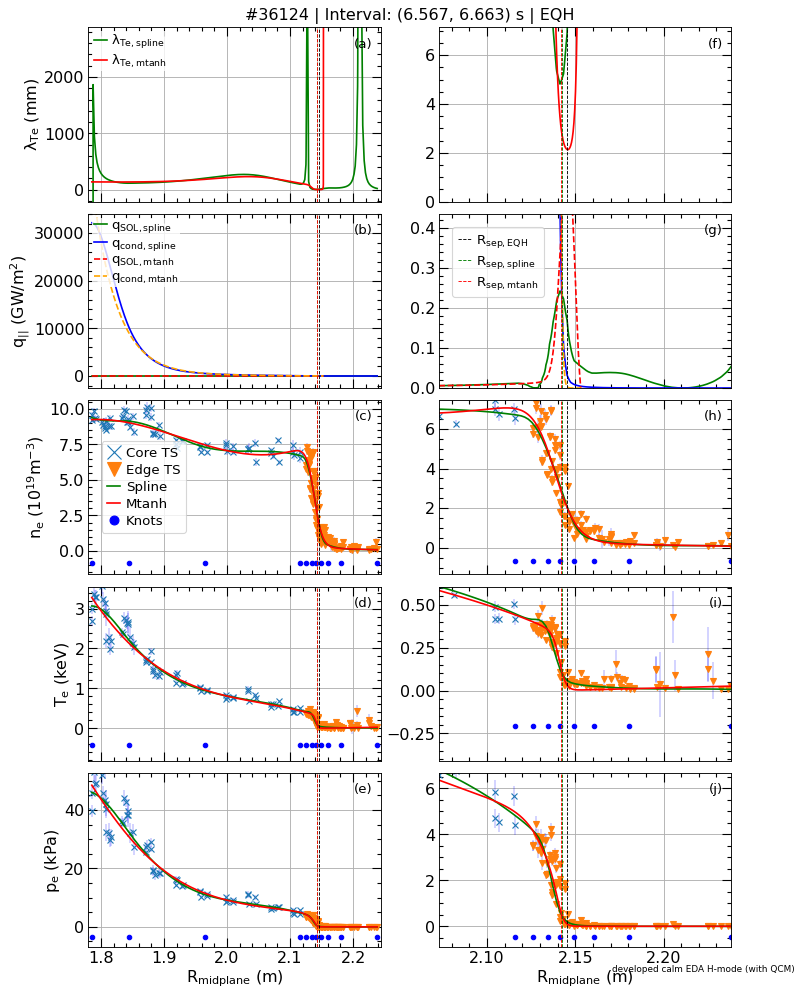

(<Figure size 803.15x992.748 with 10 Axes>,
 array([[<Axes: ylabel='$\\lambda_{Te}$ (mm)'>, <Axes: >],
        [<Axes: ylabel='$q_{||}$ ($GW/m^2$)'>, <Axes: >],
        [<Axes: ylabel='$n_e$ ($10^{19}m^{-3}$)'>, <Axes: >],
        [<Axes: ylabel='$T_e$ (keV)'>, <Axes: >],
        [<Axes: xlabel='$R_{midplane}$ (m)', ylabel='$p_e$ (kPa)'>,
         <Axes: xlabel='$R_{midplane}$ (m)'>]], dtype=object))

In [60]:
# Complete lambda, heat-flux, density, temperature, and pressure summary.
importlib.reload(plotting)
plot_profile_summary = plotting.plot_profile_summary

plot_profile_summary(
    x_core=df_plot_ne.loc[core_ne, 'r_midplane'].to_numpy(),
    x_edge=df_plot_ne.loc[edge_ne, 'r_midplane'].to_numpy(),
    ne_core=df_plot_ne.loc[core_ne, 'Ne'].to_numpy(),
    ne_edge=df_plot_ne.loc[edge_ne, 'Ne'].to_numpy(),
    te_core=df_plot_te.loc[core_te, 'Te'].to_numpy(),
    te_edge=df_plot_te.loc[edge_te, 'Te'].to_numpy(),
    ne_err_core=df_plot_ne.loc[core_ne, 'Ne_err'].to_numpy(),
    ne_err_edge=df_plot_ne.loc[edge_ne, 'Ne_err'].to_numpy(),
    te_err_core=df_plot_te.loc[core_te, 'Te_err'].to_numpy(),
    te_err_edge=df_plot_te.loc[edge_te, 'Te_err'].to_numpy(),
    ds_out=ds_out,
    R_spline=spline_result['R_grid'],
    R_mtanh=mtanh_result['R_grid'],
    te_popt=te_popt,
    ne_popt=ne_popt,
    lambda_spline=spline_result['lam_Te_grid'],
    lambda_mtanh=mtanh_result['lam_Te_grid'],
    q_sol_spline=spline_result['q_par_P_SOL_grid'],
    q_cond_spline=spline_result['q_par_SH_grid'],
    q_sol_mtanh=mtanh_result['q_par_P_SOL_grid'],
    q_cond_mtanh=mtanh_result['q_par_SH_grid'],
    q_intersection_values=[
        spline_result['q_par_P_SOL'] ,
        mtanh_result['q_par_P_SOL'] ,
    ],
    Rsep_eqh=eqh_result['Rsep_eqh'],
    Rsep_spline=spline_result['Rsep'],
    Rsep_mtanh=mtanh_result['Rsep'],
    knot_pos=knots,
    nshot=shot_id,
    interval=interval,
    equilibrium=equilibrium,
    r_zoom=r_zoom,
    directory=output_directory,
    fig_name=figure_names['summary_all'],
    save_fig=save_figures,
    show=show_figures,
    close=close_figures,
)


In [31]:
# Shot-level power and stored-energy diagnostic plot.
import ts_profile_fitter.loading as loading
import ts_profile_fitter.plotting as plotting

importlib.reload(loading)
importlib.reload(plotting)
shot_list_path = resolve_config_path('shot_list', '../configs/shot_list.csv')
shot_list_df = loading.load_shot_list(str(shot_list_path))
shot_rows = shot_list_df[shot_list_df['shot_id'].astype(int) == int(shot_id)]
shot_description = (
    shot_rows.iloc[0].get('description') if not shot_rows.empty else None
)
power_data = loading.load_power_signals(shot_id, interval=interval)

00:15:43 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/TOT/36/36124.1
00:15:43 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/TTH/36/36124.1
00:15:43 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/GQH/36/36124.1
00:15:43 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/davidp/BPT/36/36124.4
00:15:43 | aug_sfutils.sfread | ERROR: Shotfile not found for AUGD:ELM(0) #36124


Figure saved to /shares/users/work/joanune/Desktop/TS_profile_fitter/plots/shot36124_EQH_k11_t6p567-6p663_summary_all_power.png


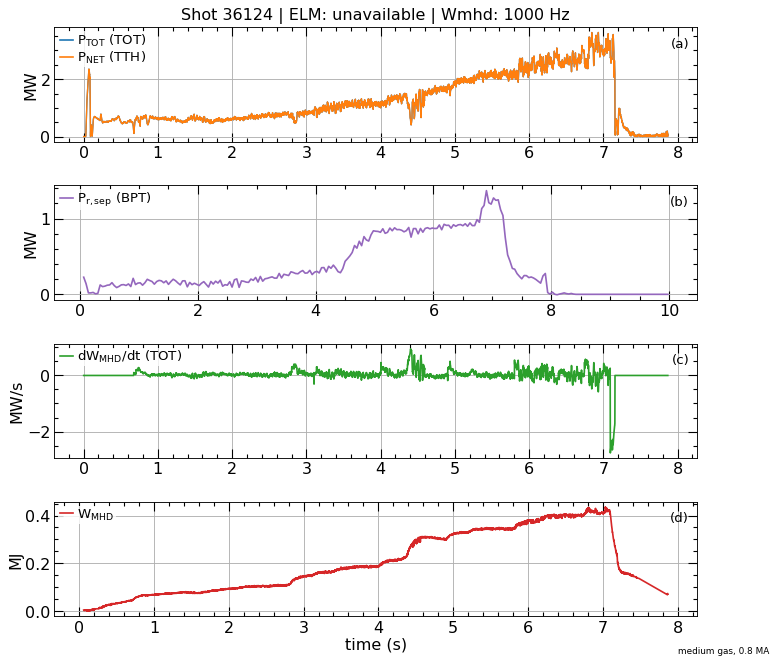

In [32]:
power_fig, power_axes = plotting.plot_power_signals(
    power_data,
    shot_id=shot_id,
    shot_description=shot_description,
    directory=output_directory,
    fig_name=figure_names['summary_all'] + '_power',
    #interval=interval,
    save_fig=True,
    h_factor = 1.5,
    close=close_figures,
    show=show_figures,
)